# BAN 612 Data Analytics
## Homework Assignment 5

- Hong Ngoc Dinh
- Nora Cook
- Hmwe Pyant Thin Chit

## Load Libraries and Dataset

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
customers = pd.read_csv("HW4_customer_cancellations.csv")

The dataset contains customer-level information such as tenure, spending, service plan,
region, customer-service contacts, payment method, satisfaction rating, and cancellation status.
The goal is to explore which factors may be associated with customer cancellations.

## Initial Data Overview

In [3]:
customers.head()

,customer_id,tenure_months,monthly_spend,total_spend,service_plan,region,customer_service_contacts,payment_method,satisfaction_rating,cancelled
0,CH00001,55,74.17,4186.14,Standard,Mountain,3,Credit Card,4,0
1,CH00002,7,133.92,889.70,Premium,West,0,Invoice,3,1
2,CH00003,70,130.84,8942.38,Premium,West,2,Bank Transfer,2,0
3,CH00004,48,53.52,2644.69,Basic,Southwest,0,Invoice,4,0
4,CH00005,16,122.43,1826.35,Premium,West,0,Invoice,5,0


In [4]:
customers.shape

(2508, 10)

In [5]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2508 entries, 0 to 2507
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2508 non-null   str    
 1   tenure_months              2508 non-null   int64  
 2   monthly_spend              2508 non-null   float64
 3   total_spend                2505 non-null   float64
 4   service_plan               2508 non-null   str    
 5   region                     2508 non-null   str    
 6   customer_service_contacts  2508 non-null   int64  
 7   payment_method             2508 non-null   str    
 8   satisfaction_rating        2508 non-null   int64  
 9   cancelled                  2508 non-null   int64  
dtypes: float64(2), int64(4), str(4)
memory usage: 271.0 KB


### Initial Observation

The dataset initially contains 2,508 rows and 10 columns. Each row represents a customer.
The variables include both numerical variables, such as tenure and spending, and categorical
variables, such as service plan, region, and payment method.

## Data Quality Assessment

Before analyzing cancellation behavior, we inspect the dataset for missing values,
duplicate records, invalid values, and unusual observations.

In [6]:
#Checking missing values
customers.isna().sum()

customer_id                  0
tenure_months                0
monthly_spend                0
total_spend                  3
service_plan                 0
region                       0
customer_service_contacts    0
payment_method               0
satisfaction_rating          0
cancelled                    0
dtype: int64

### Missing Values

There are 3 missing values in `total_spend`. No other variables initially contain missing values.
Because this is a very small proportion of the dataset, these observations will be retained
unless they interfere with a specific analysis.

In [7]:
customers[customers["total_spend"].isna()]

,customer_id,tenure_months,monthly_spend,total_spend,service_plan,region,customer_service_contacts,payment_method,satisfaction_rating,cancelled
333,CH00334,36,64.48,NaN,Basic,Northwest,0,Credit Card,4,1
1333,CH01334,3,87.24,NaN,Standard,Mountain,1,Credit Card,4,0
2333,CH02334,66,90.24,NaN,Standard,Southwest,0,AutoPay,4,1


Let's check to see what the potential values of the missing total spend data look like to see if we can estimate the missing values of total spend

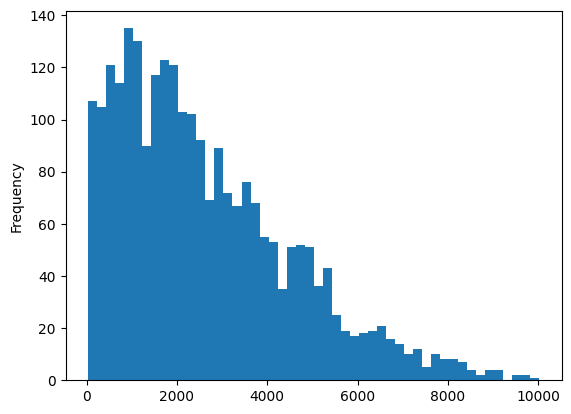

In [8]:
customers["total_spend"].plot(kind="hist",bins=50)
plt.show()


Now let's compare total spend vs monthly spend to see if there is a trend to help estimate potential values for the missing values

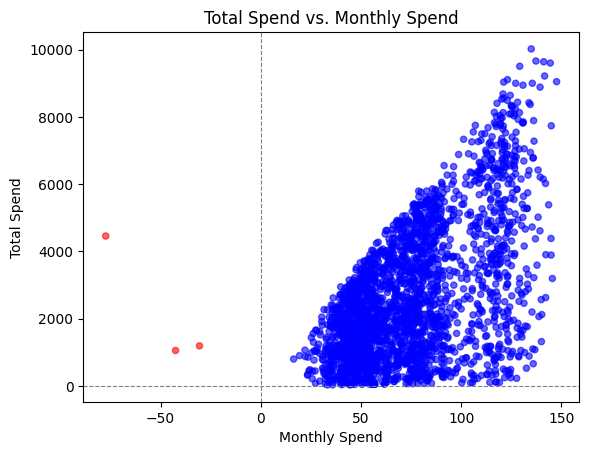

In [9]:

#  Define conditional colors (Red if negative, Blue if positive)
colors = np.where(
    (customers["monthly_spend"] < 0) | (customers["total_spend"] < 0), 
    "red", 
    "blue"
)

# Create the scatter plot with the color array
customers.plot(
    kind="scatter", 
    x="monthly_spend", 
    y="total_spend", 
    c=colors, 
    alpha=0.6  # Adds transparency so overlapping points are visible
)

#  Add labels and title
plt.title("Total Spend vs. Monthly Spend")
plt.xlabel("Monthly Spend")
plt.ylabel("Total Spend")

# Optional: Add reference lines at 0 to clearly divide negative zones
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)

plt.show()


We see that there are negative values for Monthly Spend. Let's take a closer look at these values, but keep in mind that they might not be outliers. They could be just refunds.

> Add blockquote



In [10]:
print(customers[customers['monthly_spend'] < 0])

     customer_id  tenure_months  monthly_spend  total_spend service_plan  \
210      CH00211             63         -77.39      4459.19     Standard   
1210     CH01211             26         -42.53      1056.99        Basic   
2210     CH02211             43         -30.59      1194.91        Basic   

         region  customer_service_contacts payment_method  \
210        West                          0        Invoice   
1210  Northwest                          1        Invoice   
2210   Mountain                          0        Invoice   

      satisfaction_rating  cancelled  
210                     4          0  
1210                    3          0  
2210                    5          0  


### Duplicate Records

We check both complete duplicate rows and duplicate customer IDs because each customer
should appear only once in the dataset.

In [11]:
customers.duplicated().sum()

np.int64(8)

In [12]:
customers["customer_id"].duplicated().sum()

np.int64(8)

There are 8 duplicate rows and 8 duplicate customer IDs. We therefore inspect the duplicate
records before deciding how to handle them.

In [13]:
# Look at duplicated records
customers[customers.duplicated(keep=False)].sort_values("customer_id")

,customer_id,tenure_months,monthly_spend,total_spend,service_plan,region,customer_service_contacts,payment_method,satisfaction_rating,cancelled
99,CH00100,63,38.75,2340.58,Basic,Northwest,0,Credit Card,5,0
2500,CH00100,63,38.75,2340.58,Basic,Northwest,0,Credit Card,5,0
399,CH00400,40,51.90,2114.78,Basic,Mountain,0,Invoice,5,0
2501,CH00400,40,51.90,2114.78,Basic,Mountain,0,Invoice,5,0
699,CH00700,10,114.65,1180.22,Premium,Northwest,3,Credit Card,5,0
2502,CH00700,10,114.65,1180.22,Premium,Northwest,3,Credit Card,5,0
999,CH01000,43,132.95,5279.74,Premium,Northwest,1,Credit Card,3,0
2503,CH01000,43,132.95,5279.74,Premium,Northwest,1,Credit Card,3,0
1299,CH01300,32,73.67,2161.79,Standard,Southwest,1,Bank Transfer,5,0
2504,CH01300,32,73.67,2161.79,Standard,Southwest,1,Bank Transfer,5,0


The duplicated customer IDs correspond to identical customer records. Therefore, the extra
copies can be removed while retaining one record for each customer.

## Numerical Variable Inspection

Summary statistics are used to identify unusual values and understand the ranges of the
numerical variables.

### Observations from Summary Statistics

Several values require further investigation:

- `satisfaction_rating` has a maximum value of 999, even though the other ratings appear to be on a 1–5 scale.
- `total_spend` contains 3 missing observations.
- The remaining numerical ranges appear reasonable based on the initial inspection.

### Check Satisfaction Rating Scale

We inspect all unique satisfaction-rating values to determine the expected rating scale.

In [14]:
customers["satisfaction_rating"].value_counts().sort_index()

satisfaction_rating
1       16
2      211
3      826
4      967
5      482
999      6
Name: count, dtype: int64

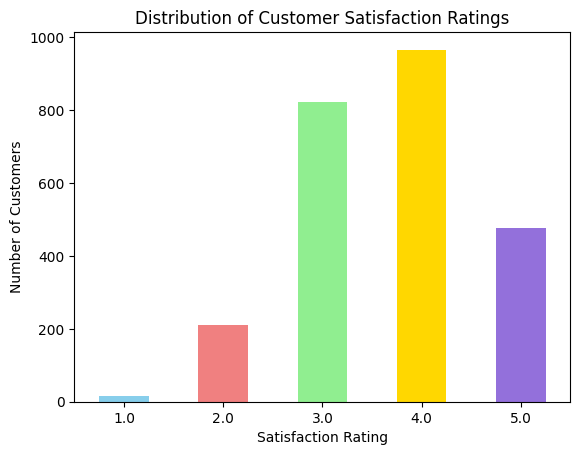

In [64]:
satisfaction_filtered = customers[customers['satisfaction_rating'] < 6]
satisfaction_counts = satisfaction_filtered['satisfaction_rating'].value_counts().sort_index()

# Define a list of colors for the bars
colors = ['skyblue', 'lightcoral', 'lightgreen', 'gold', 'mediumpurple']

satisfaction_counts.plot(kind='bar', color=colors[:len(satisfaction_counts)])

plt.title('Distribution of Customer Satisfaction Ratings')
plt.xlabel('Satisfaction Rating')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

The normal satisfaction ratings range from 1 to 5. Six observations contain a value of 999,
which is outside the observed rating scale and should therefore be treated as invalid.

## Additional Variable Validation

The remaining variables are inspected to confirm that categorical values and numerical
ranges are reasonable before cleaning the dataset.

In [16]:
customers["satisfaction_rating"].value_counts().sort_index()

satisfaction_rating
1       16
2      211
3      826
4      967
5      482
999      6
Name: count, dtype: int64

In [17]:
customers["service_plan"].value_counts(dropna=False)

service_plan
Basic       1048
Standard     950
Premium      508
basic          2
Name: count, dtype: int64

In [18]:
customers["region"].value_counts(dropna=False)

region
Mountain     644
West         627
Northwest    620
Southwest    617
Name: count, dtype: int64

In [19]:
customers["payment_method"].value_counts(dropna=False)

payment_method
Bank Transfer    658
Invoice          626
Credit Card      615
AutoPay          607
auto pay           2
Name: count, dtype: int64

In [20]:
customers["cancelled"].value_counts(dropna=False)

cancelled
0    2007
1     501
Name: count, dtype: int64

In [21]:
customers[["tenure_months",
           "total_spend",
           "customer_service_contacts"]].describe()

,tenure_months,total_spend,customer_service_contacts
count,2508.000000,2505.000000,2508.000000
mean,36.033892,2636.772870,1.273923
std,20.645527,1927.640658,1.188768
min,1.000000,33.780000,0.000000
25%,18.000000,1103.740000,0.000000
50%,35.000000,2201.860000,1.000000
75%,54.000000,3769.090000,2.000000
max,72.000000,10020.730000,7.000000


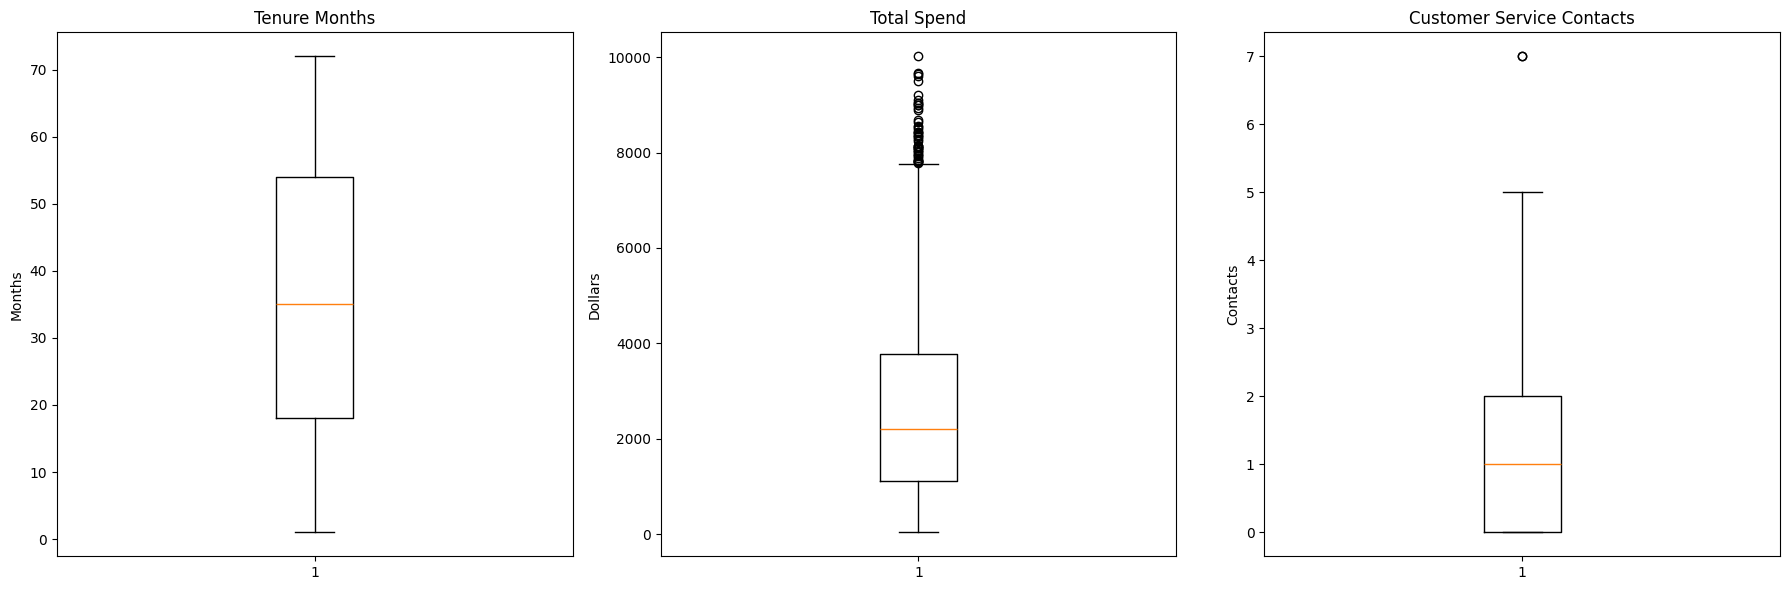

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6)) # 1 row, 3 columns, adjust figure size

# Boxplot for tenure_months
axes[0].boxplot(customers["tenure_months"])
axes[0].set_title("Tenure Months")
axes[0].set_ylabel("Months")

# Boxplot for total_spend
axes[1].boxplot(customers["total_spend"].dropna()) # Drop NaN values for plotting
axes[1].set_title("Total Spend")
axes[1].set_ylabel("Dollars")

# Boxplot for customer_service_contacts
axes[2].boxplot(customers["customer_service_contacts"])
axes[2].set_title("Customer Service Contacts")
axes[2].set_ylabel("Contacts")

plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.show()

In [23]:
customers[customers["tenure_months"] < 0]

,customer_id,tenure_months,monthly_spend,total_spend,service_plan,region,customer_service_contacts,payment_method,satisfaction_rating,cancelled


In [24]:
customers[customers["total_spend"] < 0]

,customer_id,tenure_months,monthly_spend,total_spend,service_plan,region,customer_service_contacts,payment_method,satisfaction_rating,cancelled


In [25]:
customers[customers["customer_service_contacts"] < 0]

,customer_id,tenure_months,monthly_spend,total_spend,service_plan,region,customer_service_contacts,payment_method,satisfaction_rating,cancelled


### Additional Validation Findings

Two categorical inconsistencies were identified:

- `service_plan` contains both `Basic` and `basic`, which represent the same category but use inconsistent capitalization.
- `payment_method` contains both `AutoPay` and `auto pay`, which appear to represent the same payment method with inconsistent formatting.

The `region` categories appear consistent.

For the remaining numerical variables:
- `tenure_months` contains no negative values.
- `total_spend` contains no negative values.
- `customer_service_contacts` contains no negative values.

These categorical inconsistencies should be standardized before further analysis.

## Data Cleaning

Based on the data-quality assessment, the following issues will be addressed before exploratory analysis:

1. Remove duplicate customer records.
2. Treat negative `monthly_spend` values as missing.
3. Treat invalid `satisfaction_rating` values of 999 as missing.
4. Standardize inconsistent service-plan labels.
5. Standardize inconsistent payment-method labels.

In [26]:
# Remove exact duplicate rows
customers = customers.drop_duplicates()

In [27]:
# Replace invalid negative monthly spending with missing values
customers.loc[customers["monthly_spend"] < 0, "monthly_spend"] = np.nan

In [28]:
# Replace invalid satisfaction rating of 999 with missing values
customers.loc[customers["satisfaction_rating"] == 999, "satisfaction_rating"] = np.nan

In [29]:
# Remove extra spaces from text categories
customers["service_plan"] = customers["service_plan"].str.strip()
customers["payment_method"] = customers["payment_method"].str.strip()

In [30]:
# Standardize service plan categories
customers["service_plan"] = customers["service_plan"].replace({
    "basic": "Basic"
})

In [31]:
# Standardize payment method categories
customers["payment_method"] = customers["payment_method"].replace({
    "auto pay": "AutoPay"
})

In [32]:
# Re-apply data cleaning and preparation steps
customers["service_plan"] = customers["service_plan"].str.strip()
customers["payment_method"] = customers["payment_method"].str.strip()
customers["tenure_group"] = pd.cut(
    customers["tenure_months"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=[
        "1-12 months",
        "13-24 months",
        "25-36 months",
        "37-48 months",
        "49-60 months",
        "61-72 months"
    ]
)
customers["low_satisfaction"] = customers["satisfaction_rating"].isin([1, 2])
customers["new_customer"] = customers["tenure_months"] <= 12
customers["high_service_contacts"] = customers["customer_service_contacts"] >= 3



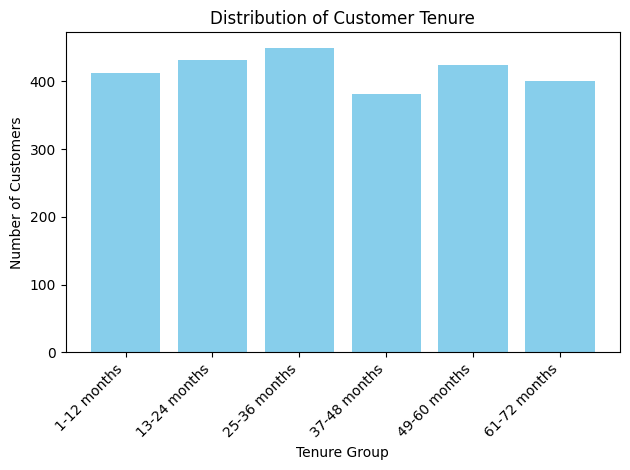

In [78]:
tenure_counts = customers["tenure_group"].value_counts(sort=False)
plt.bar(tenure_counts.index.astype(str), tenure_counts.values, color="skyblue")
plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent overlapping labels
plt.show()

## Final Cleaned Dataset Check

Before beginning exploratory analysis, the cleaned dataset is reviewed to confirm that duplicate records have been removed, inconsistent categories have been standardized, and invalid values have been handled.

In [34]:
customers.shape

(2500, 14)

In [35]:
customers.duplicated().sum()

np.int64(0)

In [36]:
customers["service_plan"].value_counts(dropna=False)

service_plan
Basic       1046
Standard     949
Premium      505
Name: count, dtype: int64

In [37]:
customers["payment_method"].value_counts(dropna=False)

payment_method
Bank Transfer    654
Invoice          625
Credit Card      612
AutoPay          609
Name: count, dtype: int64

In [38]:
customers["satisfaction_rating"].value_counts(dropna=False).sort_index()

satisfaction_rating
1.0     16
2.0    211
3.0    823
4.0    966
5.0    478
NaN      6
Name: count, dtype: int64

In [39]:
customers.isna().sum()

customer_id                  0
tenure_months                0
monthly_spend                3
total_spend                  3
service_plan                 0
region                       0
customer_service_contacts    0
payment_method               0
satisfaction_rating          6
cancelled                    0
tenure_group                 0
low_satisfaction             0
new_customer                 0
high_service_contacts        0
dtype: int64

### Missing Values After Cleaning

After cleaning, the dataset contains:

- 3 missing values in `monthly_spend`, created by replacing invalid negative spending values.
- 3 missing values in `total_spend`, which were already missing in the original dataset.
- 6 missing values in `satisfaction_rating`, created by replacing invalid values of 999.

Because these represent only a small portion of the dataset, the records are retained and the missing values will be handled appropriately during analysis.

In [40]:
customers.describe()

,tenure_months,monthly_spend,total_spend,customer_service_contacts,satisfaction_rating,cancelled
count,2500.000000,2497.000000,2497.000000,2500.000000,2494.000000,2500.00000
mean,36.035200,74.395707,2636.461434,1.275200,3.673216,0.20000
std,20.658167,27.775711,1928.309977,1.188962,0.900744,0.40008
min,1.000000,16.400000,33.780000,0.000000,1.000000,0.00000
25%,18.000000,51.590000,1103.380000,0.000000,3.000000,0.00000
50%,35.000000,71.440000,2202.440000,1.000000,4.000000,0.00000
75%,54.250000,90.180000,3769.090000,2.000000,4.000000,0.00000
max,72.000000,147.630000,10020.730000,7.000000,5.000000,1.00000


/var/folders/z0/n5kpw55x1bvcb7szytyz19dm0000gn/T/ipykernel_78585/1739439968.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=customers, y=col, ax=ax, palette="Set2")
/var/folders/z0/n5kpw55x1bvcb7szytyz19dm0000gn/T/ipykernel_78585/1739439968.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=customers, y=col, ax=ax, palette="Set2")
/var/folders/z0/n5kpw55x1bvcb7szytyz19dm0000gn/T/ipykernel_78585/1739439968.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=customers, y=col, ax=ax, palette="Set2")
/var/folders/z0/n5kpw5

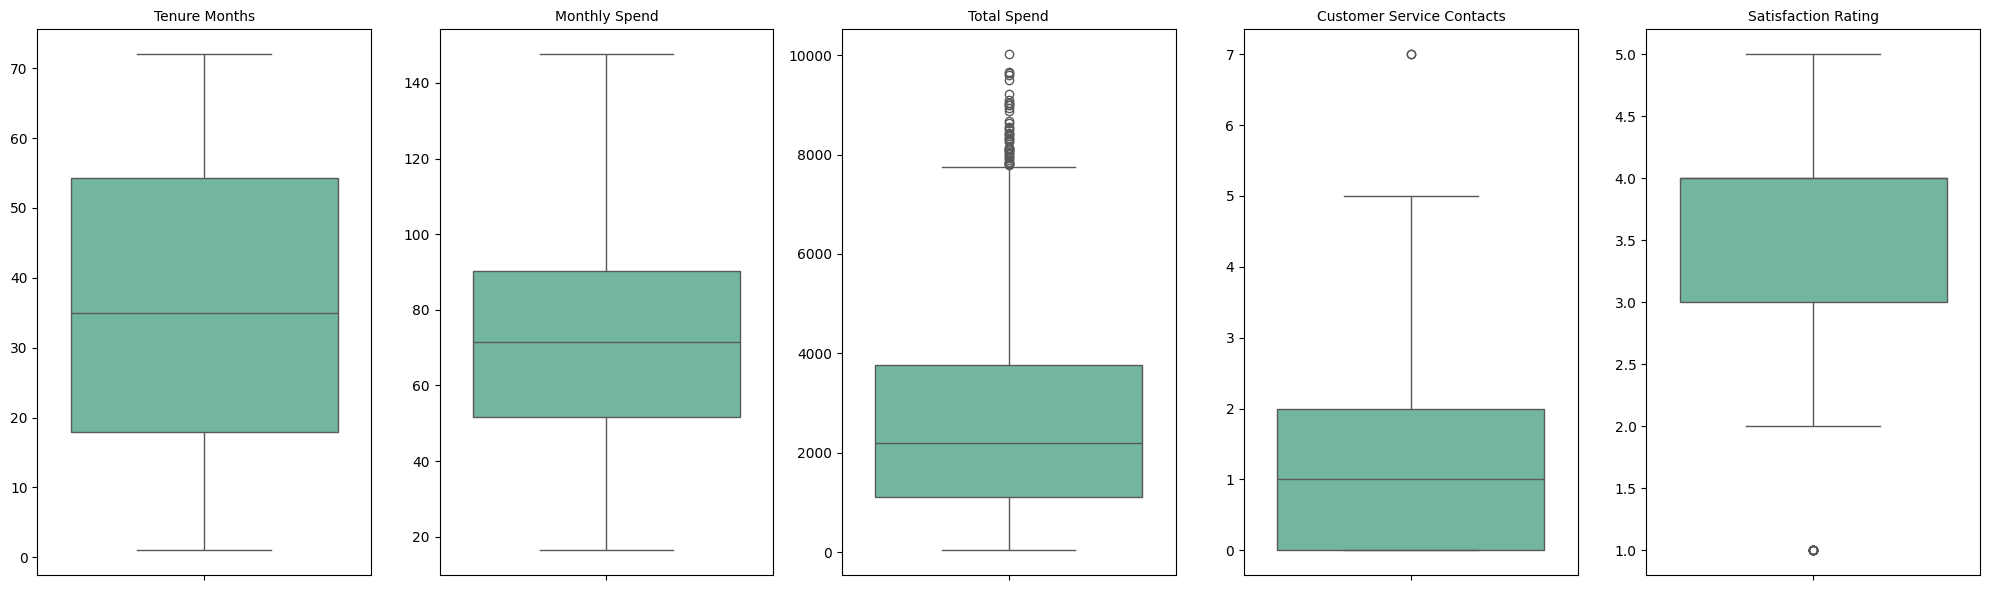

In [88]:
# Define your columns
columns = [
    "tenure_months",
    "monthly_spend",
    "total_spend",
    "customer_service_contacts",
    "satisfaction_rating",
]

# Set up a single row of subplots
# nrows=1, ncols=len(columns) ensures they all sit on the same line
fig, axes = plt.subplots(nrows=1, ncols=len(columns), figsize=(20, 6))

# Loop through columns and their corresponding axis
for col, ax in zip(columns, axes):
    # orient='v' ensures vertical boxplots
    sns.boxplot(data=customers, y=col, ax=ax, palette="Set2")

    # Clean up titles and formatting
    ax.set_title(col.replace("_", " ").title(), fontsize=10)
    ax.set_ylabel("")  # Removes redundant y-labels since title has the name

# Optimize spacing between plots
plt.tight_layout()
plt.show()

### Final Cleaning Check

The cleaned dataset contains 2,500 unique customer records. Duplicate rows have been removed, inconsistent category labels have been standardized, and invalid numerical values have been converted to missing values. The dataset is now ready for exploratory analysis of customer cancellation behavior.

## Exploratory Analysis of Customer Cancellation

The goal of this section is to investigate how cancellation varies across customer characteristics. For each analysis, a business question is stated first, followed by the analysis and interpretation.

### Business Question 1: What proportion of customers cancelled their subscription?

In [67]:
cancelled_customers = customers["cancelled"].value_counts()
cancelled_customers

cancelled
0    2000
1     500
Name: count, dtype: int64

In [68]:
percentage_cancelled_customers = customers["cancelled"].value_counts(normalize=True) * 100
percentage_cancelled_customers

cancelled
0    80.0
1    20.0
Name: proportion, dtype: float64

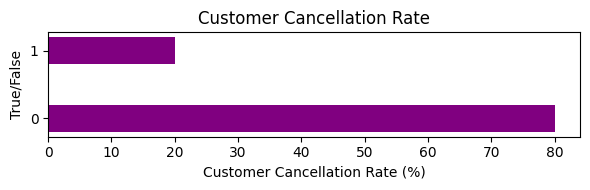

In [69]:
plt.figure(figsize=(6, 2))

# Create thin horizontal bars using the 'height' parameter
plt.barh(
    percentage_cancelled_customers.index.astype(str), 
    percentage_cancelled_customers.values, 
    height=0.4, 
    color='purple'
)

# Add relevant labels and title
plt.xlabel('Customer Cancellation Rate (%)')
plt.ylabel('True/False')
plt.title('Customer Cancellation Rate')

# Tighten the layout so elements don't get cut off
plt.tight_layout()
plt.show()


**Interpretation**

The cleaned dataset contains 2,500 customers. Of these, 500 customers cancelled their subscription and 2,000 remained. This corresponds to an overall cancellation rate of 20%.

### Business Question 2: Does customer satisfaction appear to be associated with cancellation?

In [66]:
satisfaction_rating = customers.groupby("satisfaction_rating")["cancelled"].mean() * 100
satisfaction_rating

satisfaction_rating
1.0    43.750000
2.0    41.706161
3.0    24.787363
4.0    12.008282
5.0    17.782427
Name: cancelled, dtype: float64

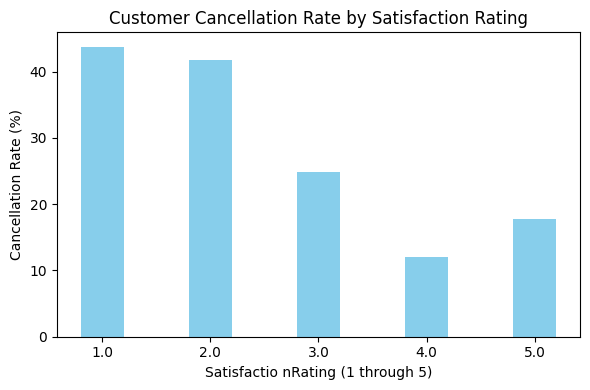

In [83]:
plt.figure(figsize=(6, 4))

# 1. Use 'width' instead of 'height' for vertical bars
plt.bar(
    satisfaction_rating.index.astype(str), 
    satisfaction_rating.values, 
    width=0.4, 
    color='skyblue'
)

# 2. Corrected labels to match a vertical bar chart
plt.xlabel('Satisfactio nRating (1 through 5)')
plt.ylabel('Cancellation Rate (%)')
plt.title('Customer Cancellation Rate by Satisfaction Rating')

plt.tight_layout()
plt.show()





#**Interpretation**

Customer satisfaction appears to be strongly associated with cancellation. Customers with satisfaction ratings of 1 and 2 have cancellation rates above 40%, which is more than double the overall cancellation rate of 20%. Customers with ratings of 4 and 5 have much lower cancellation rates, around 12%–18%.

This suggests that low customer satisfaction may be an important factor to investigate when trying to reduce cancellations.

**Managerial Meaning**

This chart helps management identify low-satisfaction customers as a higher-risk group. Customers with ratings of 1 or 2 may benefit from targeted retention efforts, service recovery, or follow-up before they decide to cancel.

### Business Question 3: Are customers with shorter tenure more likely to cancel?

In [44]:
customers.groupby("cancelled")["tenure_months"].mean()

cancelled
0    37.028
1    32.064
Name: tenure_months, dtype: float64

In [45]:
customers.groupby("cancelled")["tenure_months"].median()

cancelled
0    36.0
1    31.0
Name: tenure_months, dtype: float64

In [46]:
customers["tenure_group"] = pd.cut(
    customers["tenure_months"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=[
        "1-12 months",
        "13-24 months",
        "25-36 months",
        "37-48 months",
        "49-60 months",
        "61-72 months"
    ]
)

In [47]:
customers.groupby("tenure_group", observed=False)["cancelled"].mean() * 100

tenure_group
1-12 months     32.929782
13-24 months    16.009281
25-36 months    19.333333
37-48 months    19.109948
49-60 months    15.330189
61-72 months    17.500000
Name: cancelled, dtype: float64

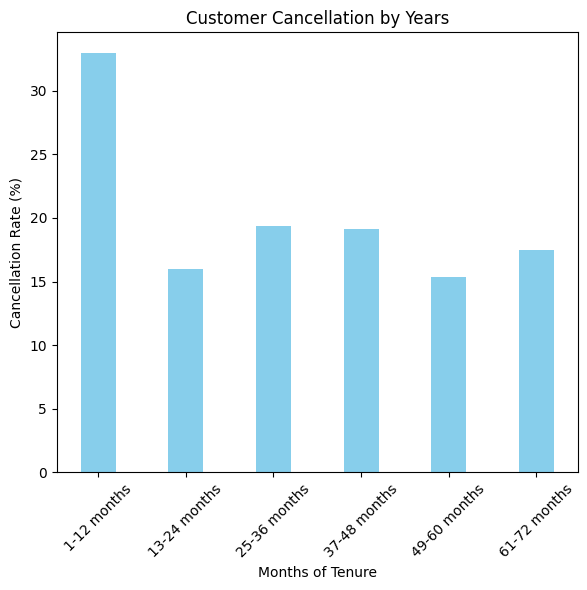

In [77]:
tenure_cancel = (
    customers.groupby("tenure_group", observed=False)["cancelled"]
    .mean() * 100
)

plt.figure(figsize=(6, 6))

# 1. Use 'width' instead of 'height' for vertical bars
plt.bar(
    tenure_cancel.index.astype(str), 
    tenure_cancel.values, 
    width=0.4, 
    color='skyblue'
)

# 2. Corrected labels to match a vertical bar chart
plt.xlabel('Months of Tenure')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=45)
plt.title('Customer Cancellation by Years')

plt.tight_layout()
plt.show()

**Interpretation**

Customers with 1–12 months of tenure have the highest cancellation rate at about 32.9%, compared with the overall cancellation rate of 20%. After the first year, cancellation rates fall to roughly 15%–19% across the remaining tenure groups.

This suggests that the first year of the customer relationship may be a particularly important period for retention efforts.

**Managerial Meaning**

This chart shows that customers in their first 12 months have a noticeably higher cancellation rate than longer-tenure customers. Management may want to focus onboarding, early engagement, and retention programs on newer customers.

### Business Question 4: Are customers who contact customer service more often more likely to cancel?

In [49]:
customers.groupby("customer_service_contacts")["cancelled"].mean() * 100

customer_service_contacts
0    18.038741
1    18.063584
2    16.521739
3    27.741935
4    41.095890
5    63.636364
7    50.000000
Name: cancelled, dtype: float64

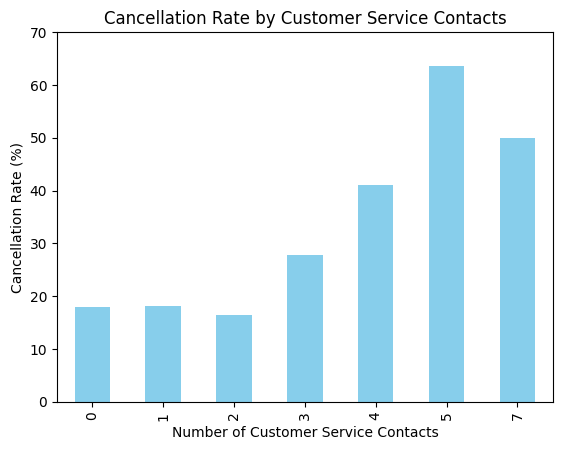

In [79]:
service_cancel = (
    customers.groupby("customer_service_contacts")["cancelled"]
    .mean() * 100
)

service_cancel.plot(kind="bar", color="skyblue")

plt.title("Cancellation Rate by Customer Service Contacts")
plt.xlabel("Number of Customer Service Contacts")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 70)
plt.show()

**Interpretation**

Customers with 0–2 customer-service contacts have cancellation rates of about 16%–18%. The cancellation rate increases noticeably for customers with 3 or more contacts, reaching about 41.1% for customers with 4 contacts and 63.6% for customers with 5 contacts.

This suggests that repeated customer-service contact may indicate unresolved problems or customer frustration and may be an important warning sign for cancellation.

**Managerial Meaning**

This chart shows that customers who contact customer service repeatedly have much higher cancellation rates. Management could monitor customers with 3 or more service contacts and prioritize them for follow-up or service recovery.

In [51]:
customers["customer_service_contacts"].value_counts().sort_index()

customer_service_contacts
0    826
1    692
2    575
3    310
4     73
5     22
7      2
Name: count, dtype: int64

### Additional Note

The 7-contact group contains only 2 customers, so its 50% cancellation rate is based on a very small sample and should be interpreted cautiously. The pattern for 3–5 contacts is more informative because those groups contain more customers.

### Business Question 5: Does cancellation vary by service plan?

In [52]:
customers.groupby("service_plan")["cancelled"].mean() * 100

service_plan
Basic       22.275335
Premium     21.386139
Standard    16.754478
Name: cancelled, dtype: float64

In [53]:
customers["service_plan"].value_counts()

service_plan
Basic       1046
Standard     949
Premium      505
Name: count, dtype: int64

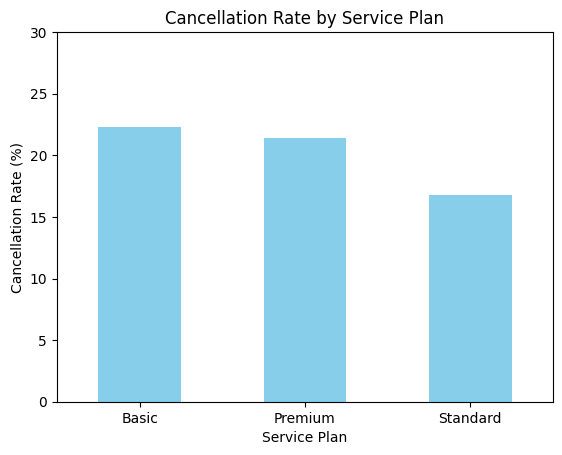

In [80]:
service_plan_cancel = (
    customers.groupby("service_plan")["cancelled"]
    .mean() * 100
)

service_plan_cancel.plot(kind="bar",color="skyblue")

plt.title("Cancellation Rate by Service Plan")
plt.xlabel("Service Plan")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 30)
plt.xticks(rotation=0)
plt.show()

**Interpretation**

Cancellation varies by service plan. Basic-plan customers have the highest cancellation rate at about 22.3%, followed by Premium customers at about 21.4%. Standard-plan customers have the lowest cancellation rate at about 16.8%.

Because all three service-plan groups contain substantial numbers of customers, these differences are meaningful enough to investigate further. Management may want to examine why Standard-plan customers appear less likely to cancel.

**Managerial Meaning**

This chart helps management compare customer retention across service plans. The lower cancellation rate among Standard-plan customers may indicate differences in pricing, value, features, or customer expectations that are worth investigating.

### Business Question 6: Does cancellation vary by payment method?

In [55]:
payment_method = customers.groupby("payment_method")["cancelled"].mean() * 100
print("Payment method by percent:\n",payment_method)

Payment method by percent:
 payment_method
AutoPay          19.540230
Bank Transfer    19.113150
Credit Card      18.954248
Invoice          22.400000
Name: cancelled, dtype: float64


In [56]:
customers["payment_method"].value_counts()

payment_method
Bank Transfer    654
Invoice          625
Credit Card      612
AutoPay          609
Name: count, dtype: int64

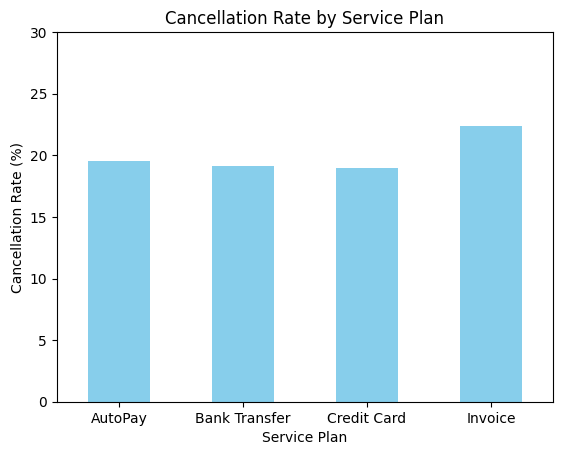

In [82]:
payment_method.plot(kind="bar",color="skyblue")

plt.title("Cancellation Rate by Service Plan")
plt.xlabel("Service Plan")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 30)
plt.xticks(rotation=0)
plt.show()

**Interpretation**

Cancellation rates are fairly similar across payment methods, ranging from about 19% to 22%. Invoice customers have the highest cancellation rate at about 22.4%, but the difference is relatively small compared with the stronger patterns seen for satisfaction, tenure, and customer-service contacts.

This suggests that payment method may be less important for explaining cancellation behavior.

## Customer Segments with Different Cancellation Rates

In [58]:
# Segment 1: Low-satisfaction customers
# (Customers with satisfaction rates of 1-2)

cancellation_rates = customers.groupby("low_satisfaction")["cancelled"].mean() * 100

cancellation_rates

low_satisfaction
False    17.817862
True     41.850220
Name: cancelled, dtype: float64

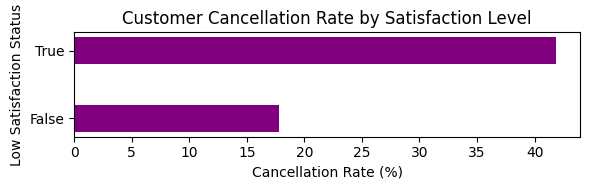

In [59]:
plt.figure(figsize=(6, 2))

# Create thin horizontal bars using the 'height' parameter
plt.barh(
    cancellation_rates.index.astype(str), 
    cancellation_rates.values, 
    height=0.4, 
    color='purple'
)

# Add relevant labels and title
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Low Satisfaction Status')
plt.title('Customer Cancellation Rate by Satisfaction Level')

# Tighten the layout so elements don't get cut off
plt.tight_layout()
plt.show()


**Segment 1: Low-Satisfaction Customers**

Customers with satisfaction ratings of 1 or 2 have a cancellation rate of about 41.9%, compared with about 17.8% for other customers.

This segment is managerially meaningful because low satisfaction appears to be strongly associated with cancellation. Management could identify dissatisfied customers early and use service recovery, follow-up, or targeted retention efforts before they leave.

In [60]:
# Segment 2: New customers
# (Customers with tenure of 1–12 months)
customers["new_customer"] = customers["tenure_months"] <= 12

new_customers = customers.groupby("new_customer")["cancelled"].mean() * 100

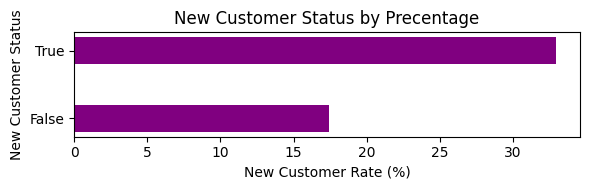

In [61]:
plt.figure(figsize=(6, 2))

# Create thin horizontal bars using the 'height' parameter
plt.barh(
    new_customers.index.astype(str), 
    new_customers.values, 
    height=0.4, 
    color='purple'
)

# Add relevant labels and title
plt.xlabel('New Customer Rate (%)')
plt.ylabel('New Customer Status')
plt.title('New Customer Status by Precentage')

# Tighten the layout so elements don't get cut off
plt.tight_layout()
plt.show()


**Segment 2: New Customers**

Customers with 12 months or less of tenure have a cancellation rate of about 32.9%, compared with about 17.4% for customers who have been with the company longer than one year.

This segment is managerially meaningful because the first year appears to be a higher-risk period. Management could improve onboarding, early engagement, and first-year retention programs.

In [62]:
# Segment 3: Customers with frequent service contacts
# (Customers with 3 or more customer-service contacts)
customers["high_service_contacts"] = customers["customer_service_contacts"] >= 3

high_service_contacts = customers.groupby("high_service_contacts")["cancelled"].mean() * 100

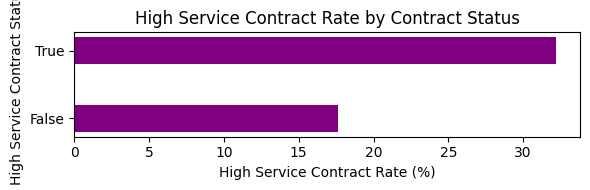

In [63]:
plt.figure(figsize=(6, 2))

# Create thin horizontal bars using the 'height' parameter
plt.barh(
    high_service_contacts.index.astype(str), 
    high_service_contacts.values, 
    height=0.4, 
    color='purple'
)

# Add relevant labels and title
plt.xlabel('High Service Contract Rate (%)')
plt.ylabel('High Service Contract Status')
plt.title('High Service Contract Rate by Contract Status')

# Tighten the layout so elements don't get cut off
plt.tight_layout()
plt.show()


**Segment 3: Customers with Frequent Service Contacts**

Customers with 3 or more customer-service contacts have a cancellation rate of about 32.2%, compared with about 17.6% for customers with fewer than 3 contacts.

This segment is managerially meaningful because repeated service contact may indicate unresolved issues or frustration. Management could flag these customers for proactive follow-up and faster issue resolution.